## Лабораторная работа №1

Вариант 0: Real Estate Valuation (регрессия) — предсказание цены дома

Источник: UCI ML Repository, ID 477

Лицензия: CC BY 4.0

ФИО: Топакова Полина Васильевна

Номер студенческого билета: 230470

Вариант: 0

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    learning_curve
)
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.inspection import permutation_importance

VARIANT = 0
RANDOM_STATE = VARIANT
TEST_SIZE = 0.2
CV_FOLDS = 5

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)

sns.set_theme(style="whitegrid")

print("Вариант:", VARIANT)
print("Random state:", RANDOM_STATE)

Вариант: 0
Random state: 0


#### Загрузка датасета
Исходные имена столбцов (x1 transaction date, x2 house age и т.д.) неудобны и содержат пробелы, поэтому переименовываем их в единый snake_case формат. Это упрощает дальнейший код и делает его читаемым.

In [ ]:
df = pd.read_excel("variant_0.xlsx")

column_mapping = {
    "no": "id",
    "x1 transaction date": "transaction_date",
    "x2 house age": "house_age",
    "x3 distance to the nearest mrt station": "distance_to_mrt",
    "x4 number of convenience stores": "n_convenience_stores",
    "x5 latitude": "latitude",
    "x6 longitude": "longitude",
    "y house price of unit area": "house_price"
}

df = df.rename(columns={
    col: column_mapping.get(str(col).strip().lower(), str(col).strip())
    for col in df.columns
})

print("Размер датасета:", df.shape)
print("\nСтолбцы:")
print(df.columns.tolist())

display(df.head())

Размер датасета: (414, 8)

Столбцы:
['id', 'transaction_date', 'house_age', 'distance_to_mrt', 'n_convenience_stores', 'latitude', 'longitude', 'house_price']


,id,transaction_date,house_age,distance_to_mrt,n_convenience_stores,latitude,longitude,house_price
0,1,2012.917,32.0,84.879,10,24.983,121.540,37.9
1,2,2012.917,19.5,306.595,9,24.980,121.540,42.2
2,3,2013.583,13.3,561.985,5,24.987,121.544,47.3
3,4,2013.500,13.3,561.985,5,24.987,121.544,54.8
4,5,2012.833,5.0,390.568,5,24.979,121.542,43.1


Вывод: датасет содержит 414 объектов и 8 столбцов. Первые строки подтверждают корректность загрузки.

#### Первичный анализ данных
Проверяем типы данных, наличие пропусков, дубликатов и выводим описательную статистику

In [ ]:
print("Типы данных:")
display(df.dtypes.to_frame("Тип данных"))

print("Количество пропусков:")
display(df.isna().sum().to_frame("Пропуски"))

print("Количество полных дубликатов:", df.duplicated().sum())

print("Описательная статистика:")
display(df.describe(include="all").T)

Типы данных:


,Тип данных
id,int64
transaction_date,float64
house_age,float64
distance_to_mrt,float64
n_convenience_stores,int64
latitude,float64
longitude,float64
house_price,float64


Количество пропусков:


,Пропуски
id,0
transaction_date,0
house_age,0
distance_to_mrt,0
n_convenience_stores,0
latitude,0
longitude,0
house_price,0


Количество полных дубликатов: 0
Описательная статистика:


,count,mean,std,min,25%,50%,75%,max
id,414.0,207.500,119.656,1.000,104.250,207.500,310.750,414.000
transaction_date,414.0,2013.149,0.282,2012.667,2012.917,2013.167,2013.417,2013.583
house_age,414.0,17.713,11.392,0.000,9.025,16.100,28.150,43.800
distance_to_mrt,414.0,1083.886,1262.110,23.383,289.325,492.231,1454.279,6488.021
n_convenience_stores,414.0,4.094,2.946,0.000,1.000,4.000,6.000,10.000
latitude,414.0,24.969,0.012,24.932,24.963,24.971,24.977,25.015
longitude,414.0,121.533,0.015,121.474,121.528,121.539,121.543,121.566
house_price,414.0,37.980,13.606,7.600,27.700,38.450,46.600,117.500


Выводы:

- Все признаки числовые (int64 и float64) — категориальных нет.

- Пропусков и дубликатов не обнаружено — данные чистые.

- Описательная статистика показывает диапазоны значений признаков и целевой переменной

Столбец id удаляется: это идентификатор объекта, а не полезный предиктор. Оставлять его в обучении нельзя — модель может «запомнить» номера и это приведёт к переобучению.

In [ ]:
TARGET = "house_price"

if TARGET not in df.columns:
    raise ValueError(
        f"Не найден столбец '{TARGET}'. "
        "Проверь названия столбцов в ячейке 2."
    )

df = df.dropna(subset=[TARGET]).drop_duplicates().copy()

if "id" in df.columns:
    df = df.drop(columns=["id"])

print("Размер после первичной очистки:", df.shape)
print("Пропуски в целевой переменной:", df[TARGET].isna().sum())

Размер после первичной очистки: (414, 7)
Пропуски в целевой переменной: 0


#### EDA: распределение целевой переменной
Строим гистограмму распределения цены единицы площади. Это позволяет увидеть форму распределения, наличие асимметрии и выбросов.

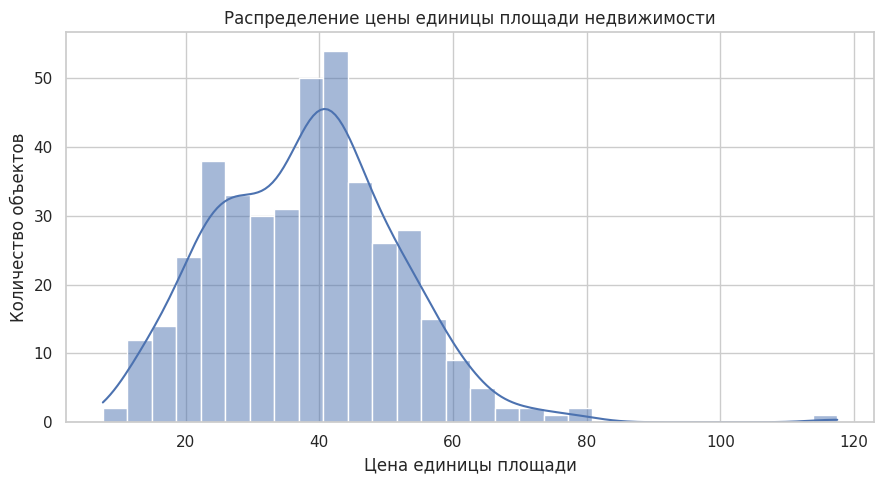

Средняя цена: 37.98
Медианная цена: 38.45
Минимальная цена: 7.6
Максимальная цена: 117.5


In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(df[TARGET], bins=30, kde=True)

plt.title("Распределение цены единицы площади недвижимости")
plt.xlabel("Цена единицы площади")
plt.ylabel("Количество объектов")
plt.tight_layout()
plt.show()

print("Средняя цена:", round(df[TARGET].mean(), 3))
print("Медианная цена:", round(df[TARGET].median(), 3))
print("Минимальная цена:", round(df[TARGET].min(), 3))
print("Максимальная цена:", round(df[TARGET].max(), 3))

Выводы: распределение близко к нормальному с правосторонней асимметрией. Средняя цена ≈ 37.98, медиана ≈ 38.45 — значения близки, значит распределение почти симметричное. Есть единичные выбросы в области высоких цен (до 117.5)

#### EDA: матрица корреляций

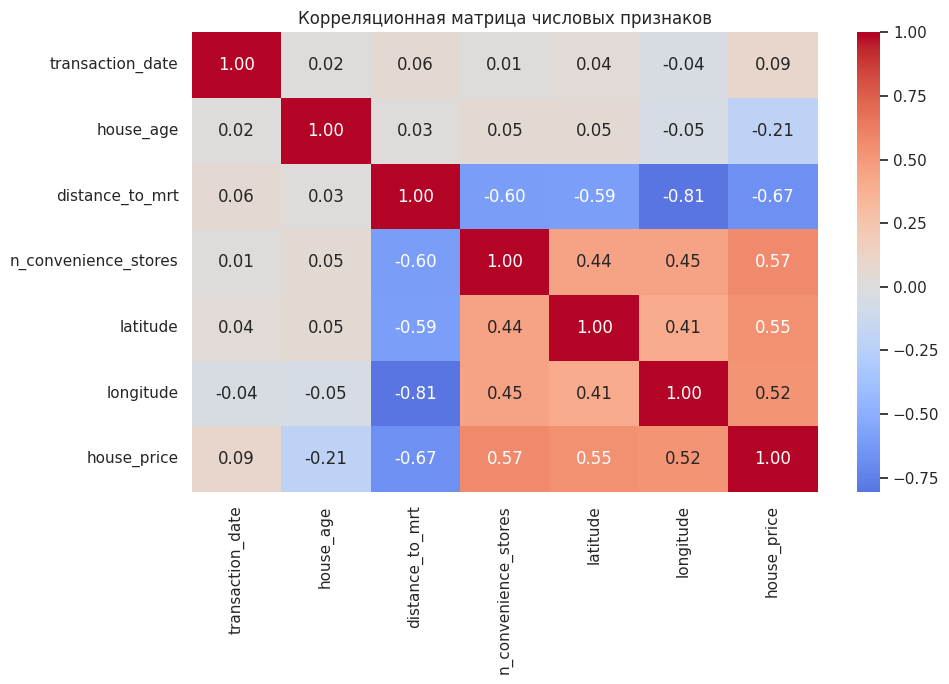

Корреляция признаков с ценой:


,Корреляция
distance_to_mrt,-0.674
n_convenience_stores,0.571
latitude,0.546
longitude,0.523
house_age,-0.211
transaction_date,0.088


In [ ]:
numeric_df = df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

target_correlations = (
    correlation_matrix[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
)

print("Корреляция признаков с ценой:")
display(target_correlations.to_frame("Корреляция"))

Выводы:

- distance_to_mrt (−0.67) — самая сильная связь (чем дальше от метро, тем ниже цена)
- n_convenience_stores (0.571) и latitude/longitude (≈0.5) — тоже значимы
- house_age (−0.211) — слабая отрицательная связь
- transaction_date (0.088) — практически не влияет

#### EDA: анализ выбросов методом IQR
Для каждого числового признака строим диаграмму размаха (boxplot) и считаем границы IQR: [Q1 − 1.5·IQR; Q3 + 1.5·IQR]. Значения за пределами считаются потенциальными выбросами.

Обоснование выбора метода IQR: он не зависит от предположения о нормальности распределения, устойчив к экстремальным значениям и широко применяется на практике.

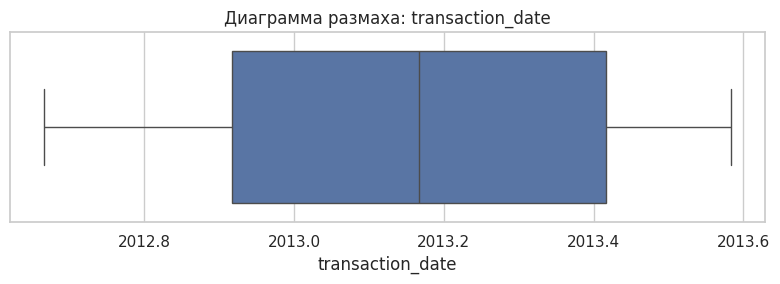

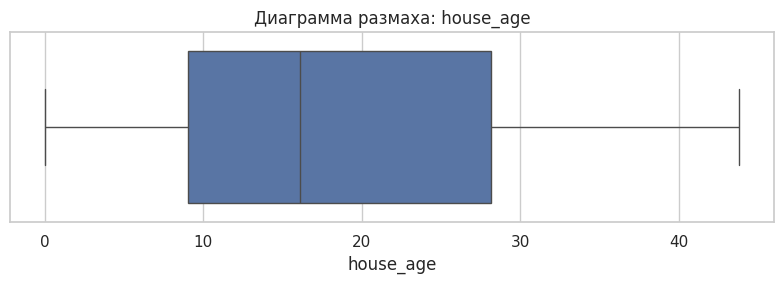

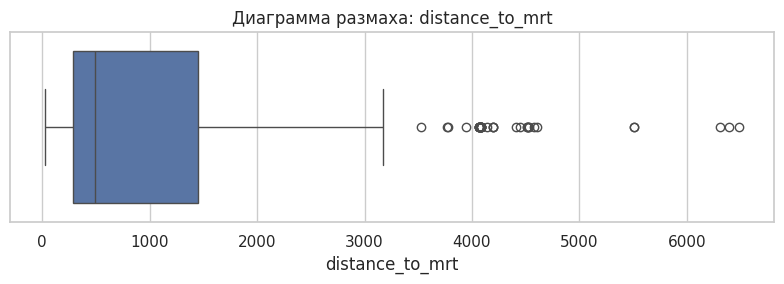

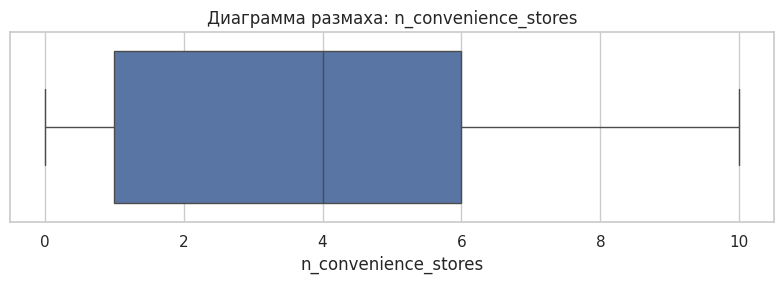

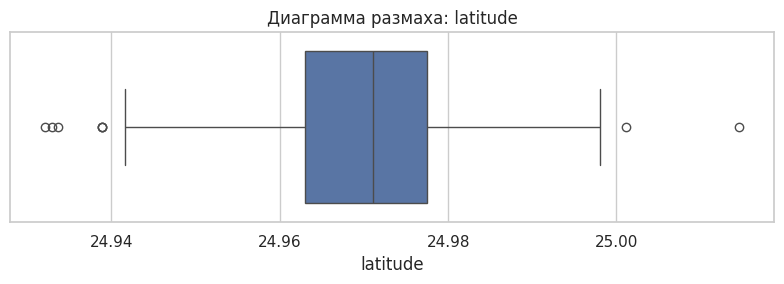

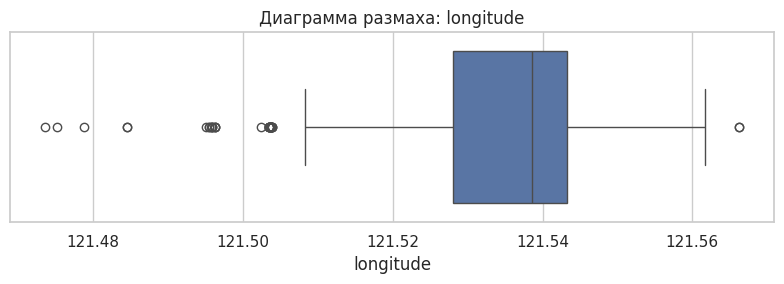

,Признак,Нижняя граница IQR,Верхняя граница IQR,Потенциальные выбросы
0,transaction_date,2012.167,2014.167,0
1,house_age,-19.663,56.837,0
2,distance_to_mrt,-1458.107,3201.710,37
3,n_convenience_stores,-6.500,13.500,0
4,latitude,24.941,24.999,8
5,longitude,121.505,121.566,35


In [ ]:
features_for_outlier_analysis = (
    df.drop(columns=[TARGET])
    .select_dtypes(include=np.number)
    .columns.tolist()
)

outlier_summary = []

for col in features_for_outlier_analysis:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])

    plt.title(f"Диаграмма размаха: {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        "Признак": col,
        "Нижняя граница IQR": lower,
        "Верхняя граница IQR": upper,
        "Потенциальные выбросы": count
    })

display(pd.DataFrame(outlier_summary))

Выбросы обнаружены только в трёх признаках:

- distance_to_mrt (37 значений). Длинный правый хвост — это реальные объекты далеко от метро (максимум ≈ 6488 м при медиане ≈ 492 м), у них низкая цена. Клиппинг здесь оправдан: он ограничит влияние экстремумов на линейную модель и KNN, не удаляя сами объекты.

- latitude (8) и longitude (35). Это координаты. «Выбросы» здесь — реальные объекты в удалённых от центральной зоны районах, а не ошибки. Клиппить координаты нельзя: обрезка сдвинула бы объект в другую точку на карте и разрушила бы сигнал о локации, которая значимо коррелирует с ценой (≈0.5). Удалять такие объекты тоже нельзя — это равносильно вырезанию целых районов из обучающей выборки.

Решение: клиппинг применяем только к признакам первой группы — тем, где крайние значения действительно являются редкими экстремумами. Координаты и дату исключаем из обработки через параметр exclude в трансформере IQRClipper.

In [ ]:
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (331, 6)
X_test: (83, 6)
y_train: (331,)
y_test: (83,)


Создаём FeatureEngineer — наследник BaseEstimator и TransformerMixin. Это позволяет встраивать его в Pipeline и GridSearchCV: все вычисления выполняются в fit/transform только на train, что исключает утечку данных.


In [ ]:
class FeatureEngineer(BaseEstimator, TransformerMixin):

    def __init__(self, enabled=True):
        self.enabled = enabled

    def fit(self, X, y=None):
        self.feature_names_in_ = list(X.columns)
        return self

    def transform(self, X):
        X_new = X.copy()

        if not self.enabled:
            return X_new

        if "distance_to_mrt" in X_new.columns:
            distance = pd.to_numeric(
                X_new["distance_to_mrt"],
                errors="coerce"
            ).clip(lower=0)

            X_new["distance_to_mrt_log"] = np.log1p(distance)

        if (
            "house_age" in X_new.columns
            and "distance_to_mrt" in X_new.columns
        ):
            age = pd.to_numeric(X_new["house_age"], errors="coerce")
            distance = pd.to_numeric(
                X_new["distance_to_mrt"],
                errors="coerce"
            )

            X_new["age_distance_interaction"] = age * distance

        if (
            "n_convenience_stores" in X_new.columns
            and "distance_to_mrt" in X_new.columns
        ):
            stores = pd.to_numeric(
                X_new["n_convenience_stores"],
                errors="coerce"
            )
            distance_km = pd.to_numeric(
                X_new["distance_to_mrt"],
                errors="coerce"
            ) / 1000

            X_new["stores_per_km_adjusted"] = (
                stores / (distance_km + 1)
            )

        return X_new

    def get_feature_names_out(self, input_features=None):
        names = list(input_features if input_features is not None
                     else self.feature_names_in_)

        if self.enabled:
            if "distance_to_mrt" in names:
                names.append("distance_to_mrt_log")

            if (
                "house_age" in names
                and "distance_to_mrt" in names
            ):
                names.append("age_distance_interaction")

            if (
                "n_convenience_stores" in names
                and "distance_to_mrt" in names
            ):
                names.append("stores_per_km_adjusted")

        return np.array(names, dtype=object)

1. distance_to_mrt_log = log1p(distance_to_mrt) — распределение расстояния до метро имеет сильную правостороннюю асимметрию: медиана ≈ 492 м, а максимум ≈ 6488 м. Логарифм сжимает длинный хвост и делает распределение ближе к нормальному. Это особенно важно для линейной модели, которая чувствительна к форме распределения признака

2. age_distance_interaction = house_age * distance_to_mrt — взаимодействие возраста дома и удалённости. Гипотеза: эффект возраста и расстояния не аддитивен. Старый дом в центре и старый дом на окраине — это разные истории. Линейная модель без такого признака не сможет уловить эту зависимость

3. stores_per_km_adjusted = stores / (distance_km + 1) — плотность инфраструктуры с поправкой на расстояние. Учитывает сразу два фактора: наличие магазинов и удалённость от метро. Знаменатель + 1 (в километрах) защищает от деления на ноль и сглаживает влияние больших расстояний

Кастомный трансформер для клиппинга выбросов

IQRClipper:
- в fit считает границы IQR только на train и сохраняет их
- в transform обрезает значения по сохранённым границам

Ключевое — параметр exclude. В него передаются признаки, которые нельзя клиппить: географические координаты (latitude, longitude) и дата сделки (transaction_date)


In [ ]:
class IQRClipper(BaseEstimator, TransformerMixin):

    def __init__(self, factor=1.5, exclude=None):
        self.factor = factor
        self.exclude = exclude if exclude is not None else []

    def fit(self, X, y=None):
        self.feature_names_in_ = list(X.columns)

        numeric_columns = X.select_dtypes(
            include=np.number
        ).columns.tolist()

        self.numeric_columns_ = [
            col for col in numeric_columns
            if col not in self.exclude
        ]

        self.bounds_ = {}

        for col in self.numeric_columns_:
            values = X[col].dropna()

            if values.empty or values.nunique() <= 2:
                continue

            q1 = values.quantile(0.25)
            q3 = values.quantile(0.75)
            iqr = q3 - q1

            self.bounds_[col] = (
                q1 - self.factor * iqr,
                q3 + self.factor * iqr
            )

        return self

    def transform(self, X):
        X_new = X.copy()

        for col, (lower, upper) in self.bounds_.items():
            if col in X_new.columns:
                X_new[col] = X_new[col].clip(
                    lower=lower,
                    upper=upper
                )

        return X_new

    def get_feature_names_out(self, input_features=None):
        if input_features is not None:
            return np.array(input_features, dtype=object)

        return np.array(self.feature_names_in_, dtype=object)

Определение типов признаков и препроцессора

In [ ]:
X_train_feature_sample = FeatureEngineer().fit_transform(X_train)

numeric_features = X_train_feature_sample.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    col for col in X_train_feature_sample.columns
    if col not in numeric_features
]

print("Числовые признаки:")
print(numeric_features)

print("\nКатегориальные признаки:")
print(categorical_features)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

transformers = [
    ("numeric", numeric_transformer, numeric_features)
]

if categorical_features:
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers.append(
        ("categorical", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

Числовые признаки:
['transaction_date', 'house_age', 'distance_to_mrt', 'n_convenience_stores', 'latitude', 'longitude', 'distance_to_mrt_log', 'age_distance_interaction', 'stores_per_km_adjusted']

Категориальные признаки:
[]


Полный пайплайн предобработки

In [ ]:
CLIP_EXCLUDE = ["latitude", "longitude", "transaction_date"]

preprocessing_pipeline = Pipeline(steps=[
    ("feature_engineering", FeatureEngineer()),
    ("outlier_clipping", IQRClipper(exclude=CLIP_EXCLUDE)),
    ("preprocessor", preprocessor)
])

X_train_processed = preprocessing_pipeline.fit_transform(X_train, y_train)
X_test_processed = preprocessing_pipeline.transform(X_test)

print("Размер X_train после предобработки:", X_train_processed.shape)
print("Размер X_test после предобработки:", X_test_processed.shape)

assert X_train_processed.shape[1] == X_test_processed.shape[1]
assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_test_processed).all()

print("Проверка пройдена: пропусков и бесконечных значений после обработки нет.")

Размер X_train после предобработки: (331, 9)
Размер X_test после предобработки: (83, 9)
Проверка пройдена: пропусков и бесконечных значений после обработки нет.


Определение базовых моделей

In [ ]:
def make_model_pipeline(model, use_engineered_features=True):

    feature_engineer = FeatureEngineer(
        enabled=use_engineered_features
    )

    return Pipeline(steps=[
        ("feature_engineering", feature_engineer),
        ("outlier_clipping", IQRClipper()),
        ("preprocessor", preprocessor),
        ("model", model)
    ])


models = {
    "Linear Regression": make_model_pipeline(
        LinearRegression()
    ),

    "KNN": make_model_pipeline(
        KNeighborsRegressor(n_neighbors=VARIANT + 2)
    ),

    "Decision Tree": make_model_pipeline(
        DecisionTreeRegressor(
            max_depth=VARIANT + 3,
            random_state=RANDOM_STATE
        )
    )
}

print("Базовые модели:")
for name, model in models.items():
    print(name, "—", model.named_steps["model"])

Базовые модели:
Linear Regression — LinearRegression()
KNN — KNeighborsRegressor(n_neighbors=2)
Decision Tree — DecisionTreeRegressor(max_depth=3, random_state=0)


#### Кросс-валидация базовых моделей
MAE интерпретируется в тех же единицах, что и цена, и устойчива к выбросам — в отличие от MSE, где одна крупная ошибка может сильно исказить среднее.

Вывод: линейная регрессия лидирует по CV, дерево решений стабильнее KNN (меньший std), KNN самый нестабильный.

In [ ]:
cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=CV_FOLDS,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    mae_scores = -scores

    cv_results.append({
        "Модель": name,
        "Средняя MAE CV": mae_scores.mean(),
        "Стандартное отклонение MAE CV": mae_scores.std()
    })

cv_table = (
    pd.DataFrame(cv_results)
    .sort_values("Средняя MAE CV")
    .reset_index(drop=True)
)

display(cv_table)

,Модель,Средняя MAE CV,Стандартное отклонение MAE CV
0,Linear Regression,5.352,0.462
1,Decision Tree,5.666,0.391
2,KNN,5.955,0.917


Оценка базовых моделей на тесте

In [ ]:
def calculate_regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


baseline_models_fitted = {}
baseline_predictions = {}
baseline_metrics = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    baseline_models_fitted[name] = model
    baseline_predictions[name] = predictions

    metrics = calculate_regression_metrics(y_test, predictions)
    metrics["Модель"] = name

    baseline_metrics.append(metrics)

baseline_table = (
    pd.DataFrame(baseline_metrics)
    [["Модель", "MAE", "RMSE", "R2"]]
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(baseline_table)

,Модель,MAE,RMSE,R2
0,Linear Regression,4.900,6.583,0.751
1,Decision Tree,5.167,7.381,0.686
2,KNN,6.257,8.647,0.570


Подбор гиперпараметров (GridSearchCV)

Так как вариант 0, используем 3 комбинации гиперпараметров для каждой модели

In [ ]:
param_grids = {
    "Linear Regression": [
        {"model__fit_intercept": [True]},
        {"model__fit_intercept": [False]},
        {
            "model__fit_intercept": [True],
            "model__positive": [True]
        }
    ],

    "KNN": [
        {"model__n_neighbors": [2]},
        {"model__n_neighbors": [3]},
        {"model__n_neighbors": [5]}
    ],

    "Decision Tree": [
        {"model__max_depth": [3]},
        {"model__max_depth": [4]},
        {"model__max_depth": [5]}
    ]
}

grid_searches = {}
grid_results = []

for name, estimator in models.items():
    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grids[name],
        scoring="neg_mean_absolute_error",
        cv=CV_FOLDS,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)
    grid_searches[name] = search

    grid_results.append({
        "Модель": name,
        "Лучшие параметры": search.best_params_,
        "Лучшая MAE CV": -search.best_score_,
        "Количество комбинаций": len(search.cv_results_["params"])
    })

grid_table = (
    pd.DataFrame(grid_results)
    .sort_values("Лучшая MAE CV")
    .reset_index(drop=True)
)

display(grid_table)

,Модель,Лучшие параметры,Лучшая MAE CV,Количество комбинаций
0,Linear Regression,{'model__fit_intercept': True},5.352,3
1,KNN,{'model__n_neighbors': 5},5.523,3
2,Decision Tree,{'model__max_depth': 5},5.535,3


Оценка настроенных моделей на тесте

Обучаем модели с лучшими параметрами и оцениваем на тесте

In [ ]:
best_models = {}
tuned_predictions = {}
tuned_metrics = []

for name, search in grid_searches.items():
    best_model = search.best_estimator_
    predictions = best_model.predict(X_test)

    best_models[name] = best_model
    tuned_predictions[name] = predictions

    metrics = calculate_regression_metrics(y_test, predictions)
    metrics["Модель"] = name
    metrics["Лучшие параметры"] = str(search.best_params_)

    tuned_metrics.append(metrics)

tuned_table = (
    pd.DataFrame(tuned_metrics)
    [["Модель", "Лучшие параметры", "MAE", "RMSE", "R2"]]
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(tuned_table)

,Модель,Лучшие параметры,MAE,RMSE,R2
0,Linear Regression,{'model__fit_intercept': True},4.900,6.583,0.751
1,KNN,{'model__n_neighbors': 5},5.215,7.070,0.712
2,Decision Tree,{'model__max_depth': 5},5.535,8.283,0.605


Сводная таблица базовых и настроенных моделей

In [ ]:
baseline_comparison = baseline_table.copy()
baseline_comparison["Версия"] = "Базовая"
baseline_comparison["Настройки"] = "Параметры варианта 0"

tuned_comparison = tuned_table.rename(
    columns={"Лучшие параметры": "Настройки"}
).copy()

tuned_comparison["Версия"] = "После GridSearchCV"

comparison_table = pd.concat(
    [
        baseline_comparison[
            ["Модель", "Версия", "Настройки", "MAE", "RMSE", "R2"]
        ],
        tuned_comparison[
            ["Модель", "Версия", "Настройки", "MAE", "RMSE", "R2"]
        ]
    ],
    ignore_index=True
).sort_values("MAE").reset_index(drop=True)

display(comparison_table)

,Модель,Версия,Настройки,MAE,RMSE,R2
0,Linear Regression,Базовая,Параметры варианта 0,4.900,6.583,0.751
1,Linear Regression,После GridSearchCV,{'model__fit_intercept': True},4.900,6.583,0.751
2,Decision Tree,Базовая,Параметры варианта 0,5.167,7.381,0.686
3,KNN,После GridSearchCV,{'model__n_neighbors': 5},5.215,7.070,0.712
4,Decision Tree,После GridSearchCV,{'model__max_depth': 5},5.535,8.283,0.605
5,KNN,Базовая,Параметры варианта 0,6.257,8.647,0.570


#### Визуализация сравнения моделей

Строим три bar-графика (по MAE, RMSE, R²), чтобы наглядно сравнить базовые и настроенные версии моделей.

Вывод: Linear Regression стабильно показывает лучшие метрики. KNN улучшился после подбора гиперпараметров, дерево решений ухудшилось.

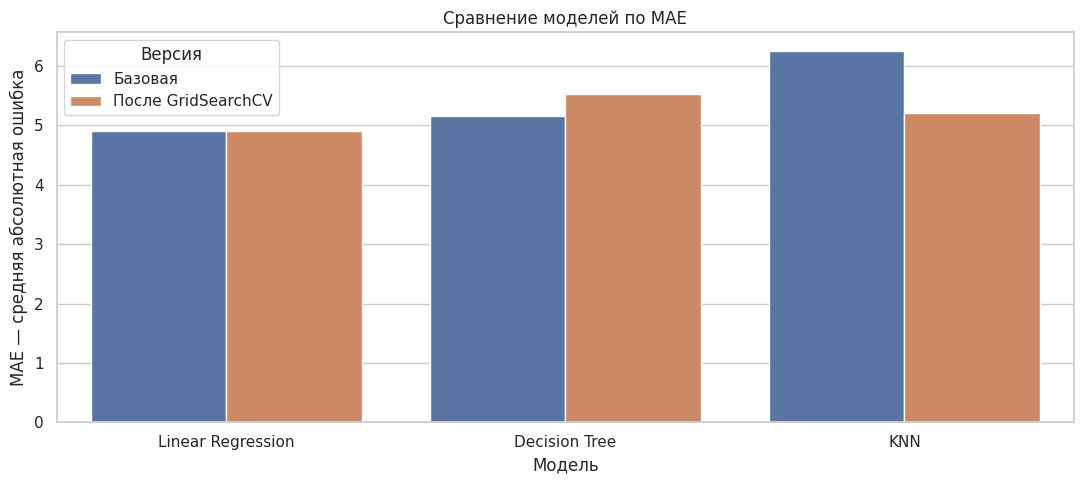

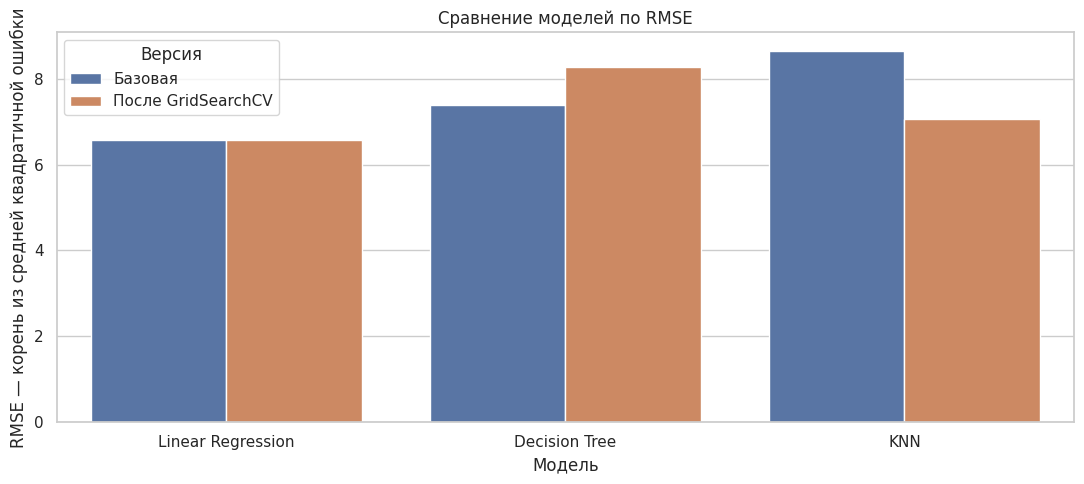

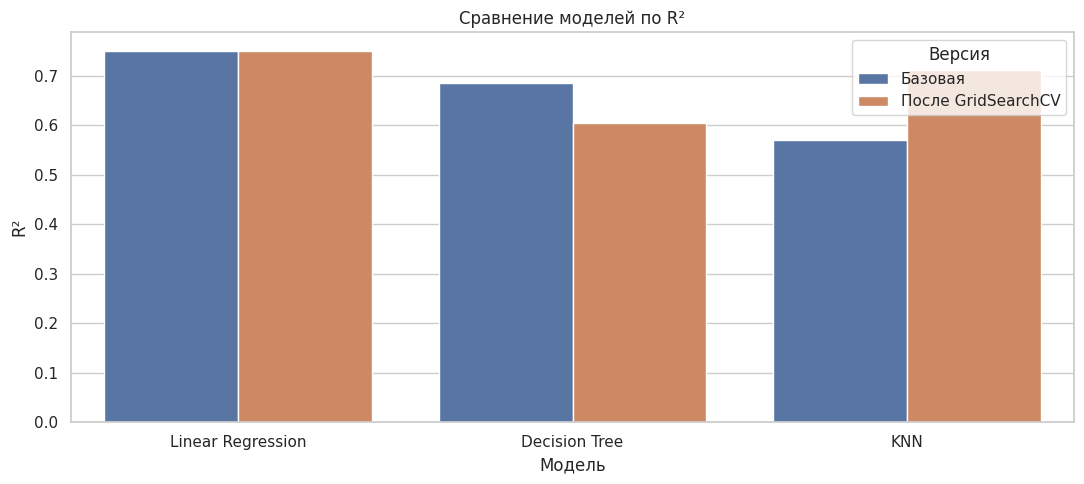

In [ ]:
# MAE
plt.figure(figsize=(11, 5))
sns.barplot(data=comparison_table, x="Модель", y="MAE", hue="Версия")

plt.title("Сравнение моделей по MAE")
plt.xlabel("Модель")
plt.ylabel("MAE — средняя абсолютная ошибка")
plt.tight_layout()
plt.show()

# RMSE
plt.figure(figsize=(11, 5))
sns.barplot(data=comparison_table, x="Модель", y="RMSE", hue="Версия")

plt.title("Сравнение моделей по RMSE")
plt.xlabel("Модель")
plt.ylabel("RMSE — корень из средней квадратичной ошибки")
plt.tight_layout()
plt.show()

# R²
plt.figure(figsize=(11, 5))
sns.barplot(data=comparison_table, x="Модель", y="R2", hue="Версия")

plt.title("Сравнение моделей по R²")
plt.xlabel("Модель")
plt.ylabel("R²")
plt.tight_layout()
plt.show()

Важность признаков

,Признак,Средняя важность,Стандартное отклонение
2,distance_to_mrt,5.950,0.869
1,house_age,1.301,0.410
5,longitude,0.749,0.414
4,latitude,0.497,0.301
3,n_convenience_stores,-0.052,0.020
0,transaction_date,-0.184,0.246


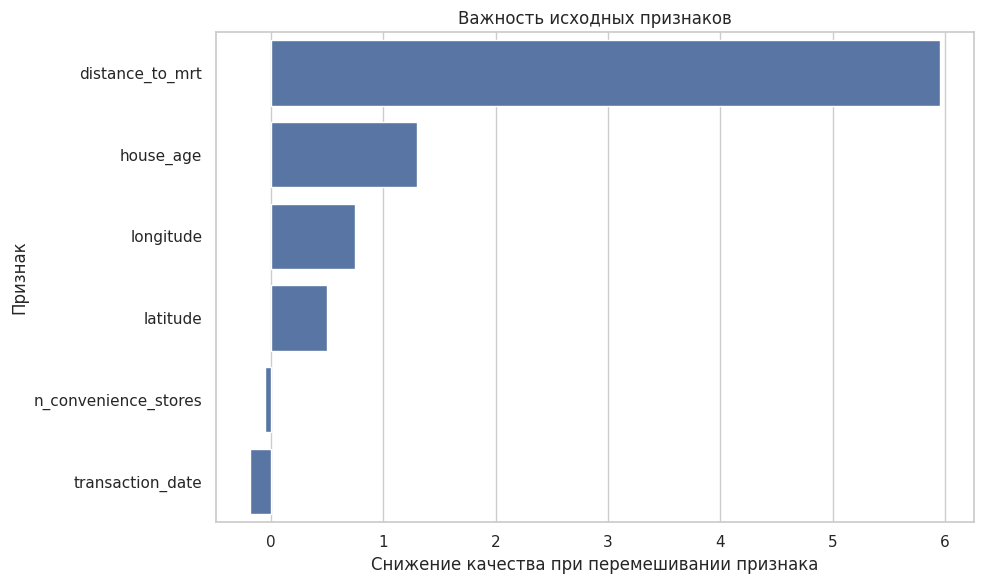

In [ ]:
permutation_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_table = pd.DataFrame({
    "Признак": X_test.columns,
    "Средняя важность": permutation_result.importances_mean,
    "Стандартное отклонение": permutation_result.importances_std
}).sort_values("Средняя важность", ascending=False)

display(importance_table)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_table,
    x="Средняя важность",
    y="Признак"
)

plt.title("Важность исходных признаков")
plt.xlabel("Снижение качества при перемешивании признака")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

1. Остатки против прогнозов — проверка на гетероскедастичность (изменение разброса остатков)
2. Факт vs прогноз — насколько точки близки к диагонали.


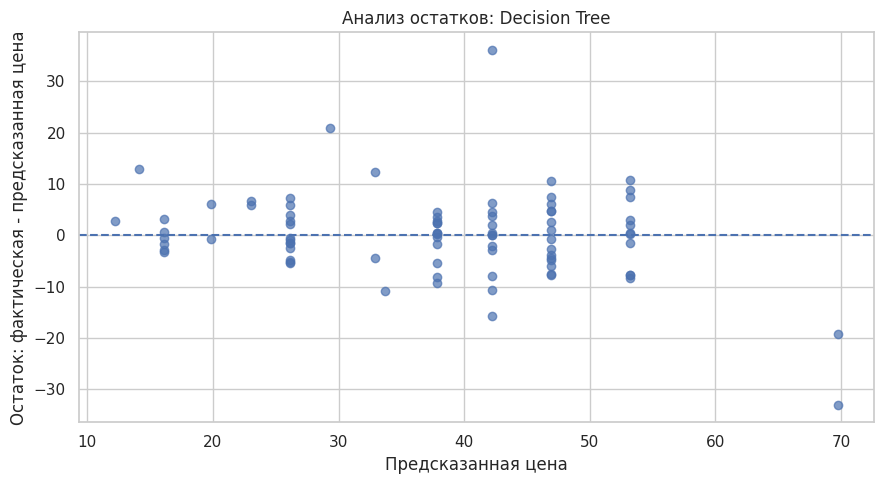

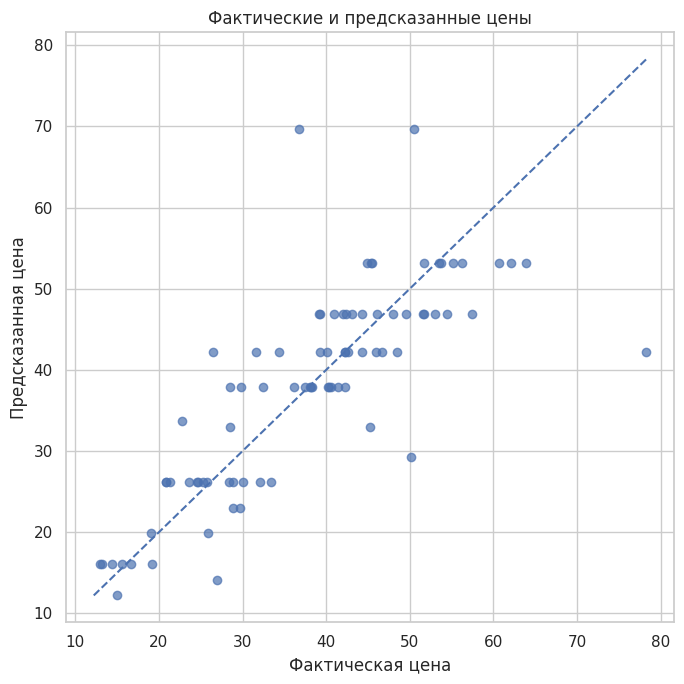

In [ ]:
y_pred_best = best_model.predict(X_test)
residuals = y_test.to_numpy() - y_pred_best

plt.figure(figsize=(9, 5))
plt.scatter(y_pred_best, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")

plt.title(f"Анализ остатков: {best_model_name}")
plt.xlabel("Предсказанная цена")
plt.ylabel("Остаток: фактическая - предсказанная цена")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_best, alpha=0.7)

min_value = min(y_test.min(), y_pred_best.min())
max_value = max(y_test.max(), y_pred_best.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Фактические и предсказанные цены")
plt.xlabel("Фактическая цена")
plt.ylabel("Предсказанная цена")
plt.tight_layout()
plt.show()

#### Кривая обучения

learning_curve показывает, как меняется качество модели при увеличении обучающей выборки. Это позволяет оценить, страдает ли модель от переобучения или недообучения.

Выводы:
- MAE на обучении растёт (1.52 → 3.57) — модель перестаёт «запоминать» данные;
- MAE на валидации падает (7.15 → 5.77) — модель лучше обобщает с ростом данных;
- кривые ещё не сошлись — модель недообучена, увеличение данных, вероятно, улучшит качество.

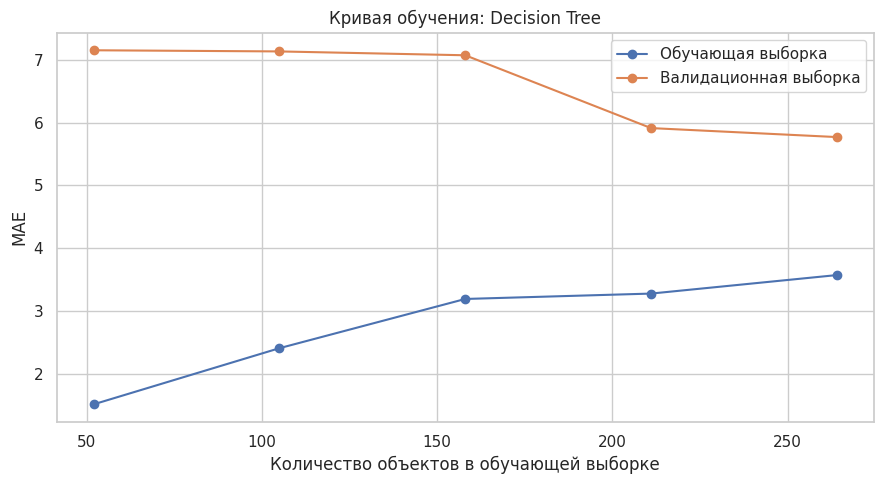

,Размер обучающей выборки,MAE на обучении,MAE на валидации
0,52,1.515,7.151
1,105,2.409,7.133
2,158,3.192,7.071
3,211,3.278,5.912
4,264,3.572,5.769


In [ ]:
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=best_model,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=CV_FOLDS,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_mae = -train_scores.mean(axis=1)
validation_mae = -validation_scores.mean(axis=1)

plt.figure(figsize=(9, 5))

plt.plot(
    train_sizes,
    train_mae,
    marker="o",
    label="Обучающая выборка"
)

plt.plot(
    train_sizes,
    validation_mae,
    marker="o",
    label="Валидационная выборка"
)

plt.title(f"Кривая обучения: {best_model_name}")
plt.xlabel("Количество объектов в обучающей выборке")
plt.ylabel("MAE")
plt.legend()
plt.tight_layout()
plt.show()

learning_curve_table = pd.DataFrame({
    "Размер обучающей выборки": train_sizes,
    "MAE на обучении": train_mae,
    "MAE на валидации": validation_mae
})

display(learning_curve_table)